In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tifffile
import fastplotlib as fpl
from clustering.utils import generate_data, SpaceTimeSVD, ClusteringCPQR

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

No windowing system present. Using surfaceless platform
No config found!
No config found!


Available devices:
✅ (default) | NVIDIA A100-SXM4-40GB | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 16.0.6, 256 bits) | CPU | Vulkan | Mesa 24.0.0-devel (git-3ca1f35cbf) (LLVM 16.0.6)
❗ | NVIDIA A100-SXM4-40GB/PCIe/SSE2 | Unknown | OpenGL | 


In [41]:
from matplotlib import pyplot as plt

In [62]:
path = "/mnt/home/kkolar/data/jason/jason/M19/D05/M19D5_MC.tif"
movie = tifffile.imread(path)[:10_000, 128:-138:2, 138:-132:2].astype(np.float32)

RFBOutputContext()

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
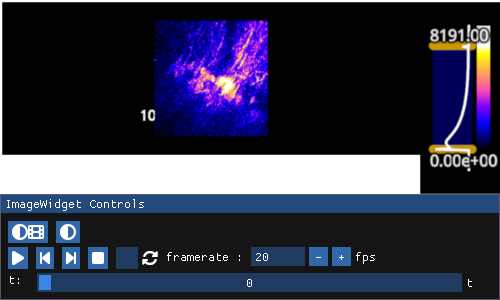

In [200]:
iw_movie = fpl.ImageWidget(movie, cmap="gnuplot2")
iw_movie.show()

In [356]:
iw_movie.figure[0, 0].add_scatter(np.fliplr(np.argwhere(overlap_pixels_img > 1)), sizes=7, colors="w", alpha=1.0)

ScatterGraphic @ 0x15542b7e8210

In [201]:
iw_movie.window_funcs = {"t": (np.mean, 33)}

In [2]:
v1 = np.load("./v_ss-2.npy")

In [3]:
xdim, ydim = 123, 121
B = v1[0].reshape(123 * 121, 123 * 121)
B = np.abs((B + B.T) / 2)

B.shape

(14883, 14883)

RFBOutputContext()

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
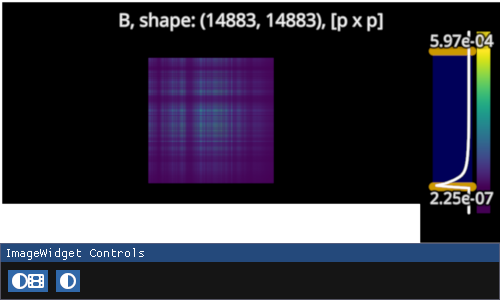

In [5]:
iw_adj = fpl.ImageWidget(
    B, 
    cmap="viridis",
    names=[f"B, shape: {B.shape}, [p x p]"]
)
iw_adj.show()

(array([ 73., 117., 179., 239., 319., 334., 471., 768., 738., 573., 509.,
        453., 477., 399., 375., 319., 320., 282., 300., 322., 266., 269.,
        251., 210., 227., 208., 207., 196., 193., 201., 201., 183., 197.,
        163., 167., 163., 193., 170., 151., 173., 158., 163., 152., 128.,
        123., 152., 142., 138., 133., 109., 107., 105.,  98., 103.,  92.,
         86.,  96.,  76.,  94.,  84.,  62.,  59.,  69.,  62.,  66.,  55.,
         52.,  47.,  56.,  35.,  34.,  43.,  41.,  30.,  50.,  35.,  39.,
         33.,  19.,  23.,  16.,  16.,  10.,   5.,  12.,   6.,   1.,   5.,
          1.,   1.,   1.,   0.,   1.,   0.,   0.,   1.,   0.,   1.,   0.,
          1.]),
 array([1.15664345e-05, 1.77116271e-05, 2.38568197e-05, 3.00020122e-05,
        3.61472048e-05, 4.22923974e-05, 4.84375900e-05, 5.45827826e-05,
        6.07279751e-05, 6.68731677e-05, 7.30183603e-05, 7.91635529e-05,
        8.53087455e-05, 9.14539381e-05, 9.75991306e-05, 1.03744323e-04,
        1.09889516e-04, 1.1603

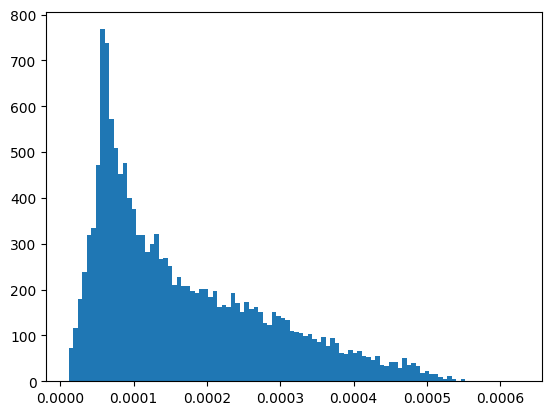

In [107]:
plt.hist(B.max(axis=1), bins=100)

In [109]:
np.argsort(B.sum(axis=0))

array([14766, 14767, 14768, ...,  8792,  8192,  8794])

In [110]:
np.sum(B[14766, :])

0.04641665180489722

In [111]:
np.sum(B[8794, :])

2.5013944978859315

In [115]:
from tqdm import tqdm

In [117]:
bg_image = np.zeros(xdim * ydim)
for i in tqdm(range(len(empty_image))):
    bg_image[i] = np.sum(B[i, :])

bg_image = bg_image.reshape((xdim, ydim))

100%|██████████████████████████████████████████████████████████████████████████████████| 14883/14883 [00:00<00:00, 75842.85it/s]


RFBOutputContext()

JupyterWgpuCanvas()
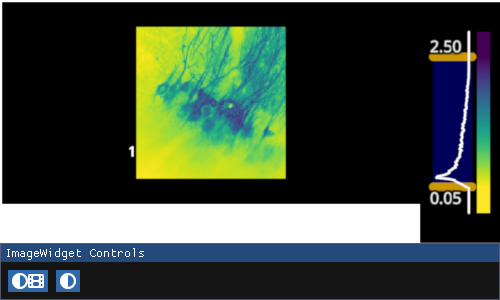

In [119]:
iw_bg = fpl.ImageWidget(bg_image, cmap="viridis_r")
iw_bg.show()

In [150]:
bg_threshold = 0.6

In [151]:
bg_ixs = B.sum(axis=1) < bg_threshold
bg_ixs

array([ True,  True,  True, ...,  True,  True,  True])

In [152]:
bg_ixs.sum()

8215

In [156]:
B2 = B[~bg_ixs][:, ~bg_ixs]

In [157]:
from scipy.linalg import qr
from scipy.sparse.linalg import eigsh

In [158]:
_, _, pivots = qr(B2, pivoting=True)
evals, Qk = eigsh(B2, k=30)

In [163]:
new_ixs = np.where(B.sum(axis=1) >= bg_threshold)[0]
new_ixs

array([   40,    51,    53, ..., 13051, 13052, 13171])

In [164]:
pivots

array([5257, 5873, 3087, ..., 4481, 4659, 4386], dtype=int32)

In [171]:
mapped_pivots = new_ixs[pivots[:50]]
mapped_pivots

array([ 8794,  9981,  5985,  6188,  8677,  9389, 10606,  8875, 10509,
        6684, 10135,  8149,  6852, 10956,  4325,  7358,  9392,  8648,
        6338,  7725, 10121,  7081,  4950,   477,  7929,  8900,   798,
         351,  1865, 10613, 10517,  6733, 11571,  8903,  5134,  1853,
        1087,  5790, 10354,  5601,  7787,   235,   952,  4580,  8639,
         354,  5178,  8212,   908,  8701])

In [172]:
pivots_img = np.zeros(xdim * ydim)
for n, i in tqdm(enumerate(mapped_pivots)):
    pivots_img[i] = n

pivots_img = pivots_img.reshape((xdim, ydim))

50it [00:00, 622300.30it/s]


In [205]:
ixs, proj = interpolative.interp_decomp(Qk.T, eps_or_k=0.001)# 50)

ValueError: too many values to unpack (expected 2)

In [381]:
Qk.nbytes

1600320

In [382]:
Qk.shape

(6668, 30)

In [383]:
import h5py

In [384]:
with h5py.File("./Qk.h5", mode="w") as f:
    f["data"] = Qk

In [ ]:
np.savetxt(

In [ ]:
np.save(

In [207]:
[k_id, ixs, proj] = interpolative.interp_decomp(Qk.T, eps_or_k=0.001)# 50)

In [208]:
mapped_id = new_ixs[ixs[:k_id]]

In [209]:
basis_img = np.zeros(xdim * ydim)
for n, i in tqdm(enumerate(mapped_id)):
    basis_img[i] = n

basis_img = basis_img.reshape((xdim, ydim))

30it [00:00, 452622.73it/s]


In [210]:
basis_img

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

RFBOutputContext()

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
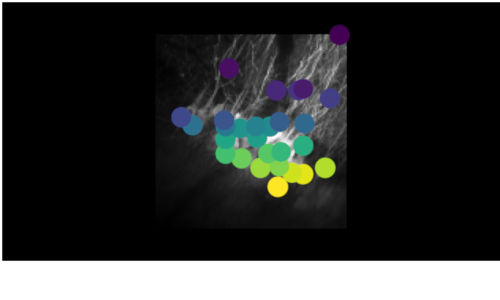

In [211]:
fig_basis = fpl.Figure()
fig_basis[0, 0].add_image(mean_movie, cmap="gray")
# fig_basis[0, 0].add_scatter(np.fliplr(np.argwhere(pivots_img > 1)), sizes=20, cmap="winter", alpha=1)
fig_basis[0, 0].add_scatter(np.fliplr(np.argwhere(basis_img > 1)), sizes=20, cmap="viridis", alpha=1)
fig_basis.show()

In [221]:
proj.shape

(30, 6638)

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 1., ..., 0., 1., 0.],
        [0., 0., 1., ..., 1., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 5., ..., 0., 0., 0.],
        [0., 0., 4., ..., 0., 1., 0.]]),
 array([-0.68493527, -0.51414561, -0.34335594, -0.17256628, -0.00177661,
         0.16901305,  0.33980272,  0.51059238,  0.68138205,  0.85217171,
         1.02296138]),
 <a list of 1000 BarContainer objects>)

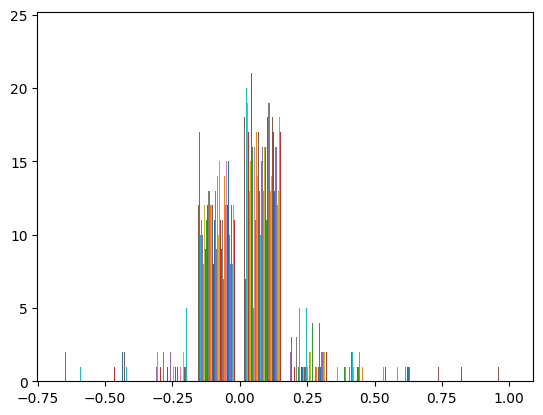

In [220]:
plt.hist(proj[:, :1000])

In [232]:
proj_ = proj.copy()
proj_[(proj_ > -0.5) & (proj_ < 0.5)] = 0

RFBOutputContext()

JupyterWgpuCanvas()
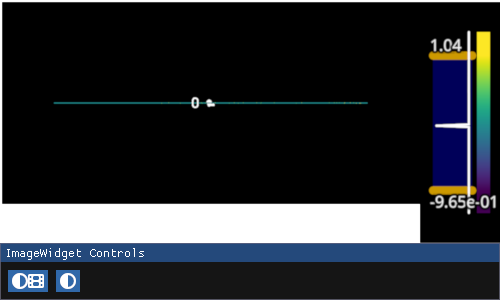

In [233]:
iw_proj = fpl.ImageWidget(proj_, cmap="viridis")
iw_proj.show()

In [236]:
proj_[proj_  < 0] = 0
proj_[proj_  > 0] = 1

RFBOutputContext()

JupyterWgpuCanvas()
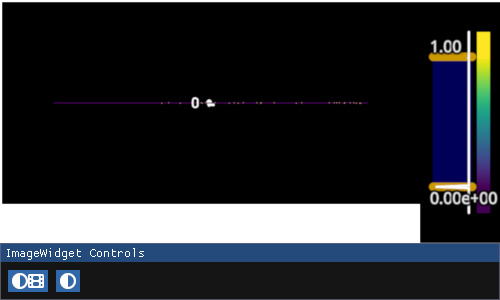

In [237]:
iw_proj = fpl.ImageWidget(proj_, cmap="viridis")
iw_proj.show()

(array([3.728e+03, 0.000e+00, 2.563e+03, 0.000e+00, 3.000e+02, 0.000e+00,
        4.000e+01, 0.000e+00, 6.000e+00, 1.000e+00]),
 array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. ]),
 <BarContainer object of 10 artists>)

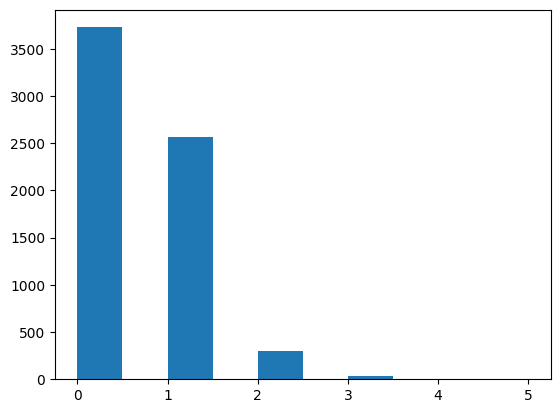

In [281]:
plt.hist(proj_.sum(axis=0))

In [238]:
ixs

array([5260, 6302, 4652, ..., 6665, 6666, 6667], dtype=int32)

In [242]:
proj.shape

(30, 6638)

In [261]:
labels_img = np.zeros((xdim * ydim))
labels_img.shape

(14883,)

In [262]:
mapped_id_all = new_ixs[ixs]
mapped_id_all.shape

(6668,)

In [263]:
mapped_id_all

array([ 8797, 10872,  7929, ..., 13051, 13052, 13171])

In [264]:
proj_[0].shape

(6638,)

In [265]:
proj_[0]

array([0., 0., 0., ..., 0., 0., 0.])

In [266]:
proj_labels = np.hstack([np.eye(k_id), proj_])
proj_labels.shape

(30, 6668)

In [269]:
proj_labels[0]

array([1., 0., 0., ..., 0., 0., 0.])

In [272]:
new_ixs[proj_labels[0] > 0]

array([  40, 5610, 5611, 5612, 5613, 5730, 5731, 5732, 5733, 5734, 5849,
       5850, 5851, 5852, 5853, 5854, 5970, 5971, 5972, 5973, 5974, 6091,
       6092, 6093, 6094, 6211, 6212, 6213, 6214, 6331, 6332, 6333, 6334,
       6335, 6452, 6453, 6454, 6455, 6573, 6574, 6575, 6694, 6695, 6696,
       6815, 6936, 7178, 7297, 8073, 8193, 8194, 8435, 8436, 8555, 8556,
       8557, 8675, 8676, 8677, 8678, 8796, 8798, 8799, 8917, 8918, 8919,
       9038, 9039, 9158])

In [273]:
for cluster_ix in range(k_id):
    labels_img[new_ixs[proj_labels[cluster_ix] > 0]] = cluster_ix

labels_img = labels_img.reshape((xdim, ydim))

RFBOutputContext()

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
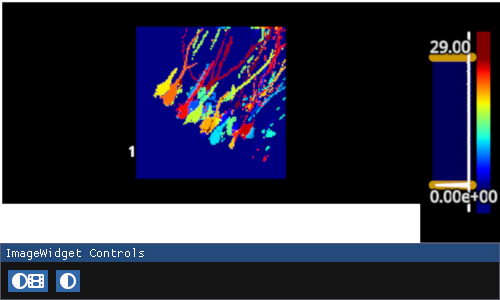

In [274]:
iw_labels = fpl.ImageWidget(labels_img, cmap="jet")
iw_labels.show()

In [282]:
labels_img

array([[ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ..., 28., 28., 28.],
       ...,
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]])

RFBOutputContext()

JupyterWgpuCanvas()
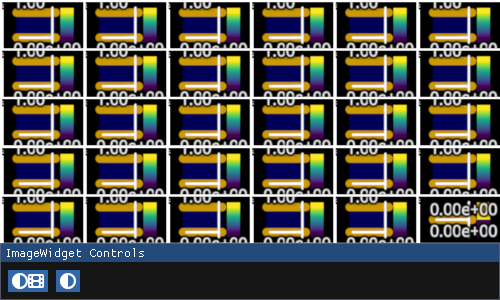

In [279]:
iw_labels_ind = fpl.ImageWidget([labels_img == i for i in range(1, k_id + 1)], cmap="viridis")
iw_labels_ind.show()

In [301]:
labels_img_alpha = np.zeros((xdim, ydim, 4))
labels_img_alpha[labels_img > 0, :-1] = [1., 0., 0.]

labels_img_alpha[labels_img > 0, -1] = 0.3

In [302]:
labels_img_alpha[:, :, -1].max()

0.3

In [305]:
labels_img == 1

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])

In [308]:
from fastplotlib.utils import make_colors

In [310]:
colors = make_colors(30, "jet")

In [336]:
ixs.shape

(6668,)

In [337]:
proj_.shape

(30, 6638)

In [346]:
overlapping_pixels = new_ixs[np.hstack([np.zeros(k_id), (proj_.sum(axis=0) > 1)]) > 0]

overlap_pixels_img = np.zeros(xdim * ydim)
for n, i in tqdm(enumerate(overlapping_pixels)):
    overlap_pixels_img[i] = n

overlap_pixels_img = overlap_pixels_img.reshape((xdim, ydim))

347it [00:00, 1837655.92it/s]


RFBOutputContext()

JupyterWgpuCanvas()
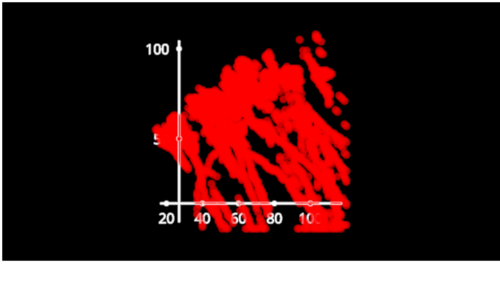

In [376]:
fig_alpha = fpl.Figure()
subplot = fig_alpha[0, 0]

for i in range(1, k_id):
    _img = np.zeros((xdim * ydim))
    _img[new_ixs[proj_labels[i] > 0]] = 1

    _img = _img.reshape((xdim, ydim))
    
    subplot.add_scatter(np.fliplr(np.argwhere(_img > 0)), sizes=7, colors="r", alpha=0.5)
    
fig_alpha.show()

In [380]:
for g in subplot.graphics:
    g.colors[:, -1] = 0.25

In [351]:
subplot.graphics[-1].sizes = 7

In [353]:
subplot.graphics[-1].colors = "w"

In [354]:
subplot.graphics[-1].alpha = 0.8